# Set Partitioning vs Set Covering vs Baseline

This notebook is a **lean, paper-oriented** comparison of three ALNS variants on the same
**20 MD-DARP instances x 20 seeds**, differing only in the hybridization strategy used:
- **baseline**: the original ALNS with no hybridization (no intra-route optimization, no set-based component)
- **set covering** (`ALNS_SC`): the ALNS with set-covering hybridization
- **set partitioning** (`ALNS_SP`): the ALNS with set-partitioning hybridization

In [1]:
from pathlib import Path
import json
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display, Markdown

# ---------------------------------------------------------
# Configuration
# ---------------------------------------------------------

BASE_DIR = Path("../data/run_base_20")
SET_BASED_DIR = Path("../data/run_set_based")

VARIANT_ORDER = ["Baseline", "Set Partitioning", "Set Covering"]
VARIANT_COLORS = {
    "Baseline": "tab:blue",
    "Set Partitioning": "tab:red",
    "Set Covering": "tab:green",
}

EXPECTED_INSTANCES = [
    "md1a", "md2a", "md3a", "md4a", "md5a",
    "md6a", "md7a", "md8a", "md9a", "md10a",
    "md1b", "md2b", "md3b", "md4b", "md5b",
    "md6b", "md7b", "md8b", "md9b", "md10b",
]
EXPECTED_SEEDS = range(1, 21)

COMPARISON_DIR = Path("../results/comparison_set_based")
COMPARISON_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.titlesize"] = 15
plt.rcParams["axes.labelsize"] = 12
plt.rcParams["lines.linewidth"] = 2
plt.rcParams["figure.dpi"] = 120

print(f"Baseline dir:    {BASE_DIR.resolve()}")
print(f"Set-Based dir: {SET_BASED_DIR.resolve()}")


Baseline dir:    /home/guillem/MD-DARP-Research/experiments/data/run_base_20
Set-Based dir: /home/guillem/MD-DARP-Research/experiments/data/run_set_based


## 1. Load all three variants

Only convergence logs and final-solution JSONs are loaded (weight-evolution logs are not
needed for this comparison, which keeps loading fast and the notebook focused).

In [2]:
# ---------------------------------------------------------
# Filename patterns
#   Baseline:    log_md1a_seed1_convergence.csv        sol_md1a_seed1.json
#   Set_based: log_md1a_seed_1_ALNS_(SP|SC)_convergence.csv   sol_md1a_seed_1_ALNS_(SP|SC).json
# ---------------------------------------------------------

BASE_CONV_PATTERN = re.compile(r"^log_?(.+?)_?seed(\d+)_convergence\.csv$")
BASE_SOL_PATTERN = re.compile(r"^sol_?(.+?)_?seed(\d+)\.json$")

SET_BASED_CONV_PATTERN = re.compile(r"^log_(.+)_seed_(\d+)_ALNS_(SP|SC)_convergence\.csv$")
SET_BASED_SOL_PATTERN = re.compile(r"^sol_(.+)_seed_(\d+)_ALNS_(SP|SC)\.json$")

# Mode code in the filename -> variant label used in the tables/plots
MODE_LABELS = {"SP": "Set Partitioning", "SC": "Set Covering"}


def load_convergence(files, pattern, variant_label, has_mode=False):
    required_cols = {
        "iteration", "elapsed_time", "current_obj", "best_obj",
        "best_feasible_obj", "destroy_op", "repair_op", "reward",
        "temperature", "segment",
    }

    frames = []
    for path in files:
        m = pattern.match(path.name)
        if not m:
            continue
        instance, seed = m.group(1), int(m.group(2))
        variant = MODE_LABELS[m.group(3)] if has_mode else variant_label

        try:
            df = pd.read_csv(path)
        except Exception as exc:
            warnings.warn(f"Could not read {path}: {exc}")
            continue

        missing = required_cols - set(df.columns)
        if missing:
            warnings.warn(f"{path.name}: missing columns {sorted(missing)}")
            continue

        df["instance"] = instance
        df["seed"] = seed
        df["variant"] = variant
        df["run_id"] = f"{instance}_seed{seed}_{variant}"

        for col in required_cols:
            df[col] = pd.to_numeric(df[col], errors="coerce")
        df["best_feasible_obj"] = df["best_feasible_obj"].replace([np.inf, -np.inf], np.nan)

        frames.append(df)

    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()


def load_solutions(files, pattern, variant_label, has_mode=False):
    rows = []
    for path in files:
        m = pattern.match(path.name)
        if not m:
            continue
        instance, seed = m.group(1), int(m.group(2))
        variant = MODE_LABELS[m.group(3)] if has_mode else variant_label

        try:
            with open(path, "r") as f:
                data = json.load(f)
        except Exception as exc:
            warnings.warn(f"Could not read {path}: {exc}")
            continue

        summary = data.get("summary", {}) if isinstance(data, dict) else {}
        rows.append({
            "instance": instance,
            "seed": seed,
            "variant": variant,
            "run_id": f"{instance}_seed{seed}_{variant}",
            "num_requests": summary.get("num_requests"),
            "num_vehicles": summary.get("num_vehicles"),
        })

    df = pd.DataFrame(rows)
    if not df.empty:
        for col in ["num_requests", "num_vehicles"]:
            df[col] = pd.to_numeric(df[col], errors="coerce")
    return df


def check_completeness(name, discovered_runs):
    missing = [
        (inst, seed) for inst in EXPECTED_INSTANCES for seed in EXPECTED_SEEDS
        if (inst, seed) not in discovered_runs
    ]
    print(f"[{name}] unique runs discovered: {len(discovered_runs)}", end="")
    if missing:
        print(f"  -- MISSING {len(missing)} runs, e.g. {missing[:5]}")
    else:
        print("  -- complete (20 x 20)")


In [3]:
# ---------------------------------------------------------
# Discover files
# ---------------------------------------------------------

base_conv_files = sorted((BASE_DIR / "alns_logs").glob("*convergence.csv"))
base_sol_files = sorted((BASE_DIR / "outputs").glob("*.json"))

set_based_conv_files = sorted((SET_BASED_DIR / "alns_logs").glob("*convergence.csv"))
set_based_sol_files = sorted((SET_BASED_DIR / "outputs").glob("*.json"))

print(f"Baseline:    {len(base_conv_files)} convergence logs, {len(base_sol_files)} solution JSONs")
print(f"Set-Based: {len(set_based_conv_files)} convergence logs, {len(set_based_sol_files)} solution JSONs "
      "(SP + SC combined)\n")

# Completeness per variant
base_runs = sorted({(m.group(1), int(m.group(2)))
                     for p in base_conv_files if (m := BASE_CONV_PATTERN.match(p.name))})
check_completeness("Baseline", base_runs)

for mode in ["SP", "SC"]:
    mode_runs = sorted({
        (m.group(1), int(m.group(2)))
        for p in set_based_conv_files
        if (m := SET_BASED_CONV_PATTERN.match(p.name))
        and m.group(3) == mode
    })
    check_completeness(f"ALNS_{mode}", mode_runs)

Baseline:    400 convergence logs, 400 solution JSONs
Set-Based: 800 convergence logs, 800 solution JSONs (SP + SC combined)

[Baseline] unique runs discovered: 400  -- complete (20 x 20)
[ALNS_SP] unique runs discovered: 400  -- complete (20 x 20)
[ALNS_SC] unique runs discovered: 400  -- complete (20 x 20)


In [4]:
# ---------------------------------------------------------
# Load convergence + solutions for all three variants and combine
# ---------------------------------------------------------

df_conv_base = load_convergence(base_conv_files, BASE_CONV_PATTERN, "Baseline", has_mode=False)
df_conv_set_based = load_convergence(set_based_conv_files, SET_BASED_CONV_PATTERN, None, has_mode=True)
df_conv_all = pd.concat([df_conv_base, df_conv_set_based], ignore_index=True)

df_sol_base = load_solutions(base_sol_files, BASE_SOL_PATTERN, "Baseline", has_mode=False)
df_sol_set_based = load_solutions(set_based_sol_files, SET_BASED_SOL_PATTERN, None, has_mode=True)
df_solutions_all = pd.concat([df_sol_base, df_sol_set_based], ignore_index=True)

print(f"Total convergence rows: {len(df_conv_all):,} across {df_conv_all['run_id'].nunique()} runs")

Total convergence rows: 11,578,282 across 1200 runs


In [5]:
# ---------------------------------------------------------
# Hybrid (set-based) performance logs
#   log_md1a_seed_1_ALNS_SP_hybrid_performance.csv
#   (= logFilePath + "_hybrid_performance.csv", same folder as the convergence logs)
# ---------------------------------------------------------

HYBRID_PATTERN = re.compile(r"^log_(.+)_seed_(\d+)_ALNS_(SP|SC)_hybrid_performance\.csv$")

hybrid_files = sorted((SET_BASED_DIR / "alns_logs").glob("*_hybrid_performance.csv"))
print(f"Hybrid performance logs found: {len(hybrid_files)}")


def load_hybrid(files):
    required = {"iteration", "num_cols", "elapsed_time", "current_obj",
                "new_obj", "status", "does_improve"}
    frames = []
    for path in files:
        m = HYBRID_PATTERN.match(path.name)
        if not m:
            continue
        instance, seed, mode = m.group(1), int(m.group(2)), m.group(3)

        try:
            df = pd.read_csv(path)
        except Exception as exc:
            warnings.warn(f"Could not read {path}: {exc}")
            continue

        missing = required - set(df.columns)
        if missing:
            warnings.warn(f"{path.name}: missing columns {sorted(missing)}")
            continue

        df["instance"], df["seed"], df["mode"] = instance, seed, mode

        for col in ["iteration", "num_cols", "elapsed_time", "current_obj", "new_obj"]:
            df[col] = pd.to_numeric(df[col], errors="coerce")
        df[["current_obj", "new_obj"]] = df[["current_obj", "new_obj"]].replace([np.inf, -np.inf], np.nan)

        df["status"] = df["status"].astype(str).str.strip()
        df["does_improve"] = df["does_improve"].astype(str).str.strip().str.lower().eq("true")
        frames.append(df)

    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()


df_hybrid_all = load_hybrid(hybrid_files)

print(f"Rows loaded: {len(df_hybrid_all):,}")
if not df_hybrid_all.empty:
    print("Iterations logged:", sorted(df_hybrid_all["iteration"].dropna().unique().astype(int))[:15])
    display(df_hybrid_all.groupby("mode")["status"].value_counts().unstack(fill_value=0))

Hybrid performance logs found: 800
Rows loaded: 2,980
Iterations logged: [np.int64(2500), np.int64(5000), np.int64(7500), np.int64(10000)]


status,Feasible (Time Limit),Optimal,Unknown
mode,,,
SC,247,929,310
SP,279,939,276


In [6]:
# ---------------------------------------------------------
# Hybrid model ablation table at iteration checkpoints
# ---------------------------------------------------------

HYBRID_MODE = "SP"                              # <-- "SP" (set partitioning) or "SC" (set covering)
HYBRID_CHECKPOINTS = [2500, 5000, 7500, 10000]
STATUS_OK = {"optimal", "feasible (time limit)"}   # statuses whose new_obj is usable
METRICS = ["Cols.", "CPU", "Imp.", "Gap"]


def build_hybrid_table(df_h, mode, checkpoints):
    d = df_h[df_h["mode"] == mode].copy()
    if d.empty:
        raise ValueError(f"No hybrid logs for mode {mode}")

    # An improvement only counts if the solver returned a usable solution
    # (Infeasible / Unknown -> treated as no improvement, gap = 0)
    usable = (
        d["status"].str.lower().isin(STATUS_OK)
        & d["new_obj"].notna() & d["current_obj"].notna() & (d["current_obj"] > 0)
    )
    d["improved"] = d["does_improve"] & usable

    with np.errstate(divide="ignore", invalid="ignore"):
        pct = 100 * (d["current_obj"] - d["new_obj"]) / d["current_obj"]
    d["gap"] = np.where(d["improved"], pct, 0.0)       # zero for runs with no improvement

    d = d[d["iteration"].isin(checkpoints)]

    per_inst = (
        d.groupby(["instance", "iteration"])
        .agg(
            cols=("num_cols", "mean"),
            cpu=("elapsed_time", "mean"),
            imp=("improved", lambda x: 100 * x.mean()),
            gap=("gap", "mean"),
            n_runs=("seed", "nunique"),
        )
        .reset_index()
    )

    # Completeness warning
    incomplete = per_inst[per_inst["n_runs"] != len(list(EXPECTED_SEEDS))]
    if not incomplete.empty:
        print(f"Warning: {len(incomplete)} instance/checkpoint cells have != 20 runs:")
        display(incomplete.head(10))

    wide = per_inst.pivot(index="instance", columns="iteration", values=["cols", "cpu", "imp", "gap"])
    name_map = {"cols": "Cols.", "cpu": "CPU", "imp": "Imp.", "gap": "Gap"}
    wide.columns = pd.MultiIndex.from_tuples(
        [(cp, name_map[m]) for m, cp in wide.columns], names=["iteration", "metric"]
    )
    wide = wide.reindex(
        index=EXPECTED_INSTANCES,
        columns=pd.MultiIndex.from_product([checkpoints, METRICS], names=["iteration", "metric"]),
    )
    wide.loc["Mean"] = wide.mean()                      # mean over instances
    return wide


hybrid_table = build_hybrid_table(df_hybrid_all, HYBRID_MODE, HYBRID_CHECKPOINTS)

display(Markdown(f"### Hybrid model performance, mode = {HYBRID_MODE}\n Cols are in thousands"))
display(
    hybrid_table
    .pipe(lambda df: df.div(
        pd.Series({
            **{(cp, "CPU"): 60 for cp in HYBRID_CHECKPOINTS},
            **{(cp, "Cols."): 1000 for cp in HYBRID_CHECKPOINTS},
        }).reindex(df.columns, fill_value=1),
        axis=1
    ))
    .round(2)
)
# ---- Status breakdown at each checkpoint (useful for the paper text) ----
status_breakdown = (
    df_hybrid_all[(df_hybrid_all["mode"] == HYBRID_MODE)
                  & df_hybrid_all["iteration"].isin(HYBRID_CHECKPOINTS)]
    .groupby(["iteration", "status"]).size().unstack(fill_value=0)
)
display(status_breakdown)


# ---- LaTeX rows, ready to paste into the table ----
def hybrid_to_latex_rows(table, checkpoints, decimals=(1, 2, 1, 2)):
    def fmt(v, dec):
        return "--" if pd.isna(v) else f"{v:.{dec}f}"

    lines = []
    for inst in table.index:
        cells = []
        for cp in checkpoints:
            for metric, dec in zip(METRICS, decimals):
                cells.append(fmt(table.loc[inst, (cp, metric)], dec))
        if inst == "Mean":
            lines.append(r"  \midrule")
            lines.append("  Mean  & " + " & ".join(cells) + r" \\")
        else:
            lines.append(f"  \\texttt{{{inst.ljust(5)}}} & " + " & ".join(cells) + r" \\")
    return "\n".join(lines)


#latex_rows = hybrid_hybrid = hybrid_to_latex_rows(hybrid_table, HYBRID_CHECKPOINTS)
#print(latex_rows)

hybrid_table.to_csv(COMPARISON_DIR / f"hybrid_table_{HYBRID_MODE}.csv")
#(COMPARISON_DIR / f"hybrid_table_{HYBRID_MODE}.tex").write_text(latex_rows)

,instance,iteration,cols,cpu,imp,gap,n_runs
2,md10a,7500,24616.692308,797.686900,61.538462,0.499641,13
5,md10b,7500,39178.909091,911.656545,0.000000,0.000000,11
41,md5a,10000,28733.529412,599.401835,23.529412,0.009929,17
45,md5b,10000,29880.307692,429.913615,30.769231,0.086141,13


### Hybrid model performance, mode = SP
 Cols are in thousands

iteration  2500                       5000                       7500          \
metric     Cols.    CPU   Imp.   Gap  Cols.    CPU   Imp.   Gap  Cols.    CPU   
instance                                                                        
md1a        1.84   0.00  45.00  0.12   2.15   0.00  10.00  0.00   2.16   0.00   
md2a        4.37   0.11  35.00  0.27   7.01   0.21  50.00  0.53   7.57   0.29   
md3a        8.72   6.89  65.00  0.47  13.15   4.38  70.00  0.49  13.54   1.82   
md4a       12.01  19.36  15.00  0.04  17.55  12.81  60.00  0.29  17.96  11.17   
md5a       14.93  20.00   0.00  0.00  25.24  20.01  10.00  0.08  28.37  17.91   
md6a       18.21  20.00   0.00  0.00  31.33  20.01   0.00  0.00  35.64  15.51   
md7a        3.20   0.02  45.00  0.43   4.88   0.03  30.00  0.19   5.14   0.02   
md8a        4.46   0.13  25.00  0.09   7.74   0.34  30.00  0.09   9.43   0.27   
md9a       13.36  19.66  20.00  0.09  19.84  17.33  30.00  0.27  20.50  14.82   
md10a      10.84  17.46  20.00  0.08  19.30  18.92  20.00  0.08  24.62  13.29   
md1b        1.35   0.00  75.00  0.08   1.47   0.00   0.00  0.00   1.47   0.00   
md2b        5.58   0.19  70.00  0.55   7.12   0.14  65.00  0.45   7.15   0.13   
md3b        8.99   3.29  80.00  0.71  13.20   3.48  90.00  1.08  13.55   1.45   
md4b       13.15  20.00  10.00  0.03  20.74  19.04  15.00  0.06  21.83  11.87   
md5b       16.47  20.00   0.00  0.00  27.22  18.59  15.00  0.17  29.73  15.20   
md6b       19.34  20.00   5.00  0.01  31.93  20.01   0.00  0.00  34.61  11.55   
md7b        2.56   0.01  80.00  0.75   2.96   0.01  15.00  0.07   2.96   0.01   
md8b        4.85   0.17  40.00  0.21   8.28   0.33  60.00  0.68  10.04   0.25   
md9b       14.40  19.91  10.00  0.03  25.37  20.01   5.00  0.01  30.39  18.95   
md10b      18.05  19.02   5.00  0.06  32.05  20.01   0.00  0.00  39.18  15.19   
Mean        9.84  10.31  32.25  0.20  15.93   9.78  28.75  0.23  17.79   7.49   

iteration               10000                      
metric      Imp.   Gap  Cols.    CPU   Imp.   Gap  
instance                                           
md1a        5.00  0.00   2.16   0.00   0.00  0.00  
md2a       15.00  0.09   7.58   0.17   0.00  0.00  
md3a       40.00  0.17  13.54   1.80   5.00  0.01  
md4a       45.00  0.09  17.96  11.94   5.00  0.00  
md5a       55.00  0.33  28.73   9.99  23.53  0.01  
md6a        5.00  0.04    NaN    NaN    NaN   NaN  
md7a       20.00  0.15   5.14   0.02   5.00  0.00  
md8a       65.00  0.58   9.61   0.15  45.00  0.16  
md9a       45.00  0.11  20.51   9.25  15.00  0.03  
md10a      61.54  0.50    NaN    NaN    NaN   NaN  
md1b        0.00  0.00   1.47   0.00   0.00  0.00  
md2b        5.00  0.02   7.15   0.13   0.00  0.00  
md3b       45.00  0.22  13.55   1.78  10.00  0.01  
md4b       40.00  0.11  21.84  11.35  25.00  0.05  
md5b       50.00  0.31  29.88   7.17  30.77  0.09  
md6b       20.00  0.04    NaN    NaN    NaN   NaN  
md7b        0.00  0.00   2.96   0.01   0.00  0.00  
md8b       80.00  0.59  10.20   0.17  30.00  0.09  
md9b       25.00  0.08  30.76  10.93  40.00  0.10  
md10b       0.00  0.00    NaN    NaN    NaN   NaN  
Mean       31.08  0.17  13.94   4.05  14.64  0.03

status,Feasible (Time Limit),Optimal,Unknown
iteration,,,
2500,102,210,88
5000,77,219,104
7500,63,254,67
10000,37,256,17


## 2. Run-level summary and joint RPD reference

In [7]:
# ---------------------------------------------------------
# One row per (instance, seed, variant) run + joint best-known reference
# ---------------------------------------------------------

run_rows = []
for (instance, seed, variant), g in df_conv_all.groupby(["instance", "seed", "variant"], sort=False):
    g = g.sort_values("iteration")
    feasible = g["best_feasible_obj"].dropna()
    run_rows.append({
        "instance": instance,
        "seed": seed,
        "variant": variant,
        "elapsed_time_sec": g["elapsed_time"].max(),
        "best_feasible_objective": feasible.min() if not feasible.empty else np.nan,
    })

df_runs_all = pd.DataFrame(run_rows)
df_runs_all = df_runs_all.merge(
    df_solutions_all[["instance", "seed", "variant", "num_requests", "num_vehicles"]],
    on=["instance", "seed", "variant"], how="left",
)

df_runs_all["regime"] = df_runs_all["instance"].str[-1].str.upper()
df_runs_all["size_id"] = df_runs_all["instance"].str.extract(r"md(\d+)[ab]", expand=False).astype(int)

# Joint best-known reference per instance, across all three variants
joint_reference = (
    df_runs_all.groupby("instance")["best_feasible_objective"].min().rename("instance_best").reset_index()
)
df_runs_all = df_runs_all.merge(joint_reference, on="instance", how="left")
df_runs_all["RPD_percent"] = (
    100 * (df_runs_all["best_feasible_objective"] - df_runs_all["instance_best"]) / df_runs_all["instance_best"]
)

print(f"Total runs loaded: {len(df_runs_all)}  (expect {len(EXPECTED_INSTANCES) * len(list(EXPECTED_SEEDS)) * 3})")
display(df_runs_all.groupby("variant").size().rename("runs").to_frame())


Total runs loaded: 1200  (expect 1200)


,runs
variant,
Baseline,400
Set Covering,400
Set Partitioning,400


## 3. Main comparison table

Per-instance mean RPD and mean runtime for each variant, with a final **aggregated** row
(pooled mean across all runs/instances).

In [8]:
# ---------------------------------------------------------
# Main comparison table: per instance + aggregate row
# ---------------------------------------------------------

per_instance = (
    df_runs_all
    .groupby(["instance", "regime", "size_id", "variant"])
    .agg(
        mean_RPD=("RPD_percent", "mean"),
        mean_best_feasible_objective=("best_feasible_objective", "mean"),
        mean_runtime_sec=("elapsed_time_sec", "mean"))
    .reset_index()
)

pivot_rpd = per_instance.pivot(index=["instance", "regime", "size_id"], columns="variant", values="mean_RPD")
pivot_obj = per_instance.pivot(index=["instance", "regime", "size_id"], columns="variant", values="mean_best_feasible_objective")
pivot_rt = per_instance.pivot(index=["instance", "regime", "size_id"], columns="variant", values="mean_runtime_sec")

pivot_rpd = pivot_rpd[VARIANT_ORDER].add_suffix(" — RPD (%)")
pivot_obj = pivot_obj[VARIANT_ORDER].add_suffix(" — best feasible objective")
pivot_rt = pivot_rt[VARIANT_ORDER].add_suffix(" — runtime (s)")

main_table = pivot_rpd.join([pivot_obj, pivot_rt]).reset_index().sort_values(["regime", "size_id"])

# Aggregate row: pooled mean across ALL runs (all instances, all seeds)
agg_row = {"instance": "ALL (aggregated)", "regime": "-", "size_id": np.nan}
for v in VARIANT_ORDER:
    agg_row[f"{v} — RPD (%)"] = df_runs_all.loc[df_runs_all["variant"] == v, "RPD_percent"].mean()
    agg_row[f"{v} — best feasible objective"] = df_runs_all.loc[df_runs_all["variant"] == v, "best_feasible_objective"].mean()
    agg_row[f"{v} — runtime (s)"] = df_runs_all.loc[df_runs_all["variant"] == v, "elapsed_time_sec"].mean()

main_table = pd.concat([main_table, pd.DataFrame([agg_row])], ignore_index=True)

display(main_table.round(3))


,instance,regime,size_id,Baseline — RPD (%),Set Partitioning — RPD (%),Set Covering — RPD (%),Baseline — best feasible objective,Set Partitioning — best feasible objective,Set Covering — best feasible objective,Baseline — runtime (s),Set Partitioning — runtime (s),Set Covering — runtime (s)
0,md1a,A,1.0,0.039,0.015,0.015,308.687,308.614,308.614,47.008,46.820,53.983
1,md2a,A,2.0,2.485,2.018,1.893,539.162,536.706,536.046,303.592,340.281,365.149
2,md3a,A,3.0,2.289,1.851,1.845,695.180,692.208,692.165,880.224,1670.242,1867.238
3,md4a,A,4.0,1.753,1.524,1.446,840.140,838.255,837.606,1832.086,4514.758,4871.441
4,md5a,A,5.0,3.743,3.708,3.741,1016.989,1016.653,1016.975,3041.188,6485.814,6726.541
5,md6a,A,6.0,2.128,2.874,3.113,1214.446,1223.313,1226.157,4883.856,7200.330,7200.468
6,md7a,A,7.0,1.593,1.302,1.302,406.156,404.992,404.992,167.388,155.297,135.093
7,md8a,A,8.0,3.150,2.944,3.148,748.784,747.293,748.777,1249.984,1397.858,1387.133
8,md9a,A,9.0,1.822,1.649,1.679,891.973,890.456,890.723,2608.468,5891.370,5782.500
9,md10a,A,10.0,4.115,7.597,8.461,1190.039,1229.828,1239.712,6046.314,7200.478,7200.492


In [9]:
# Remove runs without a feasible solution
valid_runs = df_runs_all.dropna(subset=["best_feasible_objective"]).copy()

# For each (instance, variant), find the run with the best objective.
# If multiple seeds achieve the same objective, take the fastest one.
best_idx = (
    valid_runs
    .sort_values(
        ["instance", "variant",
         "best_feasible_objective", "elapsed_time_sec",
         "seed"]
    )
    .groupby(["instance", "variant"], as_index=False)
    .head(1)
)

# Keep only the relevant columns
best_per_instance = best_idx[
    [
        "instance",
        "variant",
        "seed",
        "best_feasible_objective",
        "elapsed_time_sec",
    ]
].copy()

# Pivot objective
pivot_best_obj = (
    best_per_instance
    .pivot(
        index="instance",
        columns="variant",
        values="best_feasible_objective"
    )
    .reindex(columns=VARIANT_ORDER)
    .add_suffix(" — best objective")
)

# Pivot runtime corresponding to the best objective
pivot_best_time = (
    best_per_instance
    .pivot(
        index="instance",
        columns="variant",
        values="elapsed_time_sec"
    )
    .reindex(columns=VARIANT_ORDER)
    .add_suffix(" — runtime (s)")
)

# Pivot seed that achieved the best objective
pivot_best_seed = (
    best_per_instance
    .pivot(
        index="instance",
        columns="variant",
        values="seed"
    )
    .reindex(columns=VARIANT_ORDER)
    .add_suffix(" — seed")
)

# Combine
best_table = (
    pivot_best_obj
    .join([pivot_best_time, pivot_best_seed])
    .reset_index()
)

# Add regime and size
best_table["regime"] = best_table["instance"].str[-1].str.upper()
best_table["size_id"] = (
    best_table["instance"]
    .str.extract(r"md(\d+)[ab]", expand=False)
    .astype(int)
)

# Sort
best_table = best_table.sort_values(
    ["regime", "size_id", "instance"]
)

# Reorder columns
best_table = best_table[
    ["instance", "regime", "size_id"]
    + [f"{v} — best objective" for v in VARIANT_ORDER]
    + [f"{v} — runtime (s)" for v in VARIANT_ORDER]
    + [f"{v} — seed" for v in VARIANT_ORDER]
]

display(best_table.round(3))

variant,instance,regime,size_id,Baseline — best objective,Set Partitioning — best objective,Set Covering — best objective,Baseline — runtime (s),Set Partitioning — runtime (s),Set Covering — runtime (s),Baseline — seed,Set Partitioning — seed,Set Covering — seed
2,md1a,A,1,308.567,308.567,308.567,40.273,39.305,44.071,7,8,7
4,md2a,A,2,530.014,526.089,526.089,276.517,307.728,429.388,18,8,8
6,md3a,A,3,683.610,679.626,679.626,820.751,1195.790,1171.400,7,20,20
8,md4a,A,4,825.669,825.669,825.669,1737.170,3206.230,3959.460,16,16,16
10,md5a,A,5,980.301,980.301,980.301,2760.200,5227.610,6433.460,8,8,8
12,md6a,A,6,1189.460,1189.140,1197.900,4544.570,7200.350,7200.360,12,20,12
14,md7a,A,7,399.786,399.786,399.786,136.977,134.691,131.003,16,6,8
16,md8a,A,8,725.921,730.301,732.005,1544.470,1660.110,1203.480,10,3,18
18,md9a,A,9,876.011,876.011,876.011,2243.990,5892.680,5582.790,12,12,12
0,md10a,A,10,1143.000,1165.530,1165.800,5252.200,7200.160,7200.790,1,20,20


## 4. Which variant wins, per instance?

For each instance: which variant achieves the lowest mean RPD (best quality), and which is
fastest (lowest mean runtime)? Counts are tallied across the 20 instances.

In [10]:
# ---------------------------------------------------------
# Win counts: best-quality variant and fastest variant, per instance
# ---------------------------------------------------------

quality_winner = per_instance.loc[
    per_instance.groupby("instance")["mean_RPD"].idxmin(), ["instance", "variant"]
].rename(columns={"variant": "best_quality_variant"})

speed_winner = per_instance.loc[
    per_instance.groupby("instance")["mean_runtime_sec"].idxmin(), ["instance", "variant"]
].rename(columns={"variant": "fastest_variant"})

win_summary = pd.DataFrame({
    "Best quality (lowest RPD) — # instances": quality_winner["best_quality_variant"].value_counts(),
    "Fastest — # instances": speed_winner["fastest_variant"].value_counts(),
}).reindex(VARIANT_ORDER).fillna(0).astype(int)

display(win_summary)


,Best quality (lowest RPD) — # instances,Fastest — # instances
Baseline,5,16
Set Partitioning,5,2
Set Covering,10,2


## 5. Mean RPD by variant (per instance + aggregate)

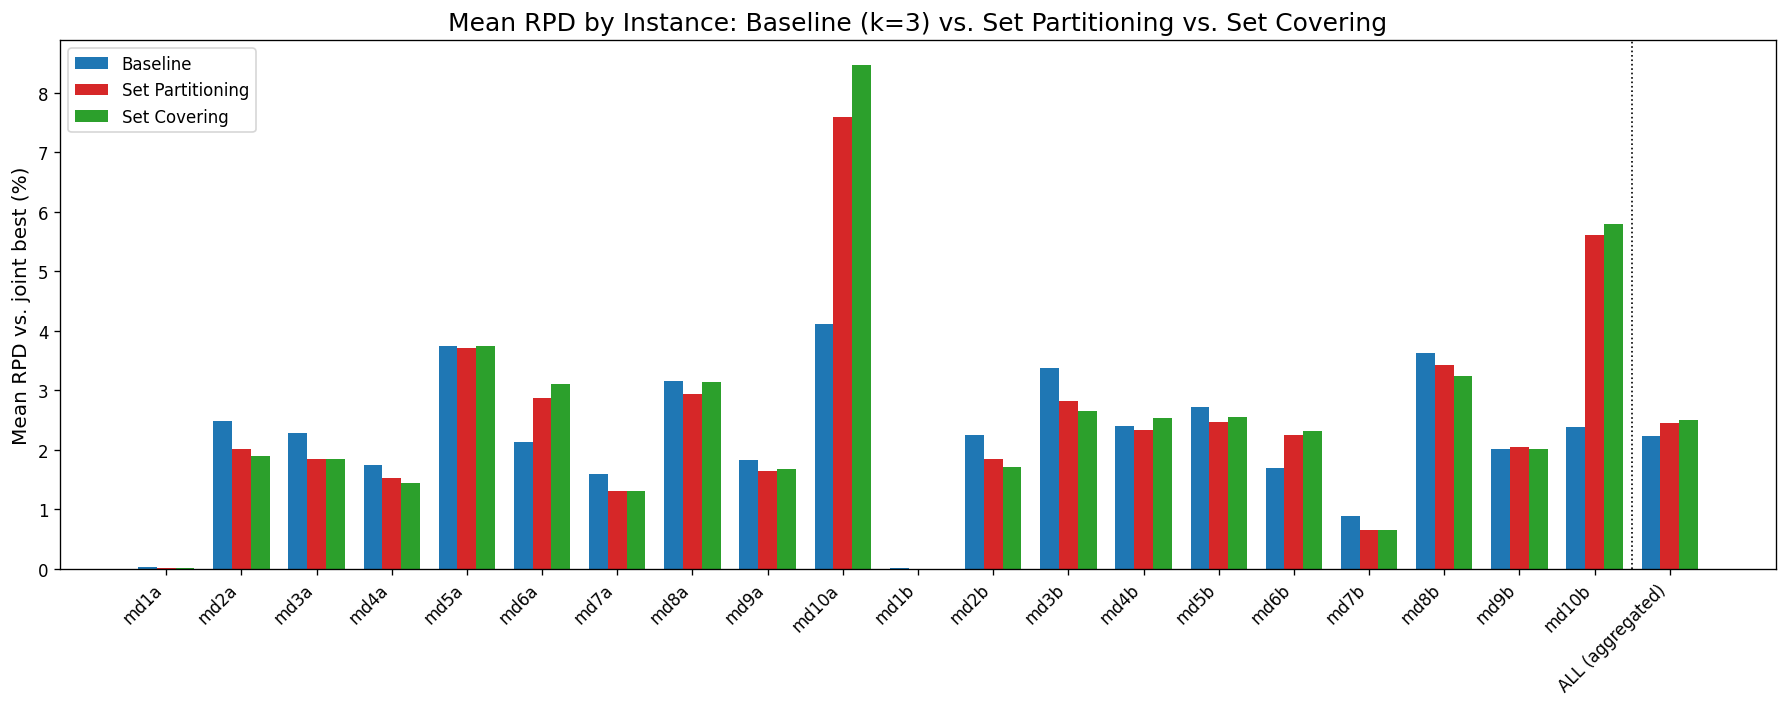

In [11]:
# ---------------------------------------------------------
# Grouped bar chart: mean RPD per instance (+ aggregate), one group per variant
# ---------------------------------------------------------

plot_df = main_table.copy()
x_labels = plot_df["instance"].tolist()
x = np.arange(len(x_labels))
width = 0.25

fig, ax = plt.subplots(figsize=(15, 6))

for i, v in enumerate(VARIANT_ORDER):
    ax.bar(x + (i - 1) * width, plot_df[f"{v} — RPD (%)"], width, label=v, color=VARIANT_COLORS[v])

ax.set_xticks(x)
ax.set_xticklabels(x_labels, rotation=45, ha="right")
ax.axvline(len(x_labels) - 1.5, color="black", linewidth=1, linestyle=":")
ax.set_ylabel("Mean RPD vs. joint best (%)")
ax.set_title("Mean RPD by Instance: Baseline (k=3) vs. Set Partitioning vs. Set Covering")
ax.legend()

plt.tight_layout()
plt.show()


## 6. Aggregate convergence comparison

Normalized search progress vs. median best-feasible RPD (against the joint reference),
pooled across all instances and seeds for each variant.

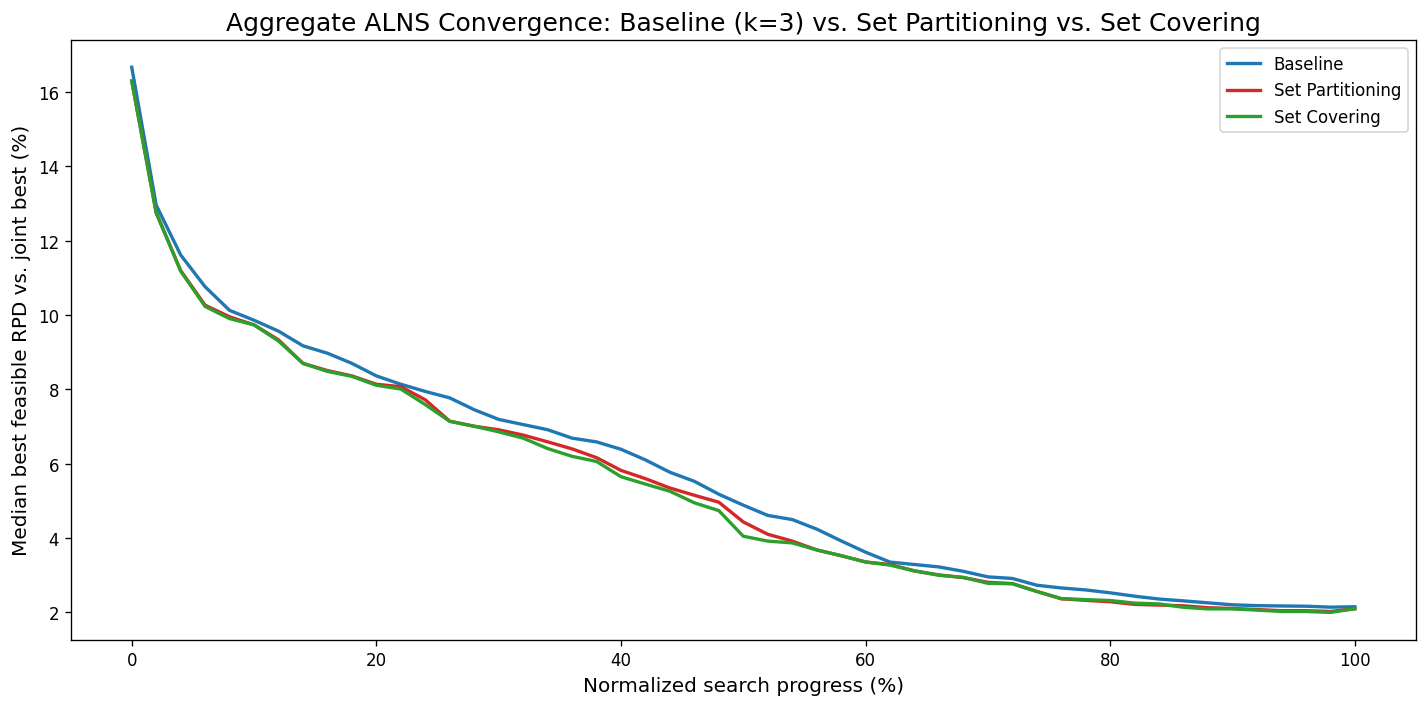

In [12]:
# ---------------------------------------------------------
# Aggregate, normalized convergence curves for the three variants
# ---------------------------------------------------------

conv_for_curve = df_conv_all.merge(joint_reference, on="instance", how="left")
conv_for_curve["feasible_RPD"] = (
    100 * (conv_for_curve["best_feasible_obj"] - conv_for_curve["instance_best"]) / conv_for_curve["instance_best"]
)
conv_for_curve["iteration_progress"] = (
    conv_for_curve.groupby("run_id")["iteration"].transform(lambda x: 100 * x / max(x.max(), 1))
)
conv_for_curve["progress_bin"] = np.floor(conv_for_curve["iteration_progress"] / 2) * 2

aggregate_curve = (
    conv_for_curve.dropna(subset=["feasible_RPD"])
    .groupby(["variant", "progress_bin"])["feasible_RPD"]
    .median()
    .reset_index()
)

fig, ax = plt.subplots(figsize=(12, 6))
for v in VARIANT_ORDER:
    g = aggregate_curve[aggregate_curve["variant"] == v]
    ax.plot(g["progress_bin"], g["feasible_RPD"], label=v, color=VARIANT_COLORS[v])

ax.set_xlabel("Normalized search progress (%)")
ax.set_ylabel("Median best feasible RPD vs. joint best (%)")
ax.set_title("Aggregate ALNS Convergence: Baseline (k=3) vs. Set Partitioning vs. Set Covering")
ax.legend()

plt.tight_layout()
plt.show()


## 7. Export tables

In [13]:
# ---------------------------------------------------------
# Export the two tables for direct use in the paper
# ---------------------------------------------------------

main_table.to_csv(COMPARISON_DIR / "main_comparison_table.csv", index=False)
win_summary.to_csv(COMPARISON_DIR / "win_summary.csv")

print(f"Exported tables to: {COMPARISON_DIR.resolve()}")


Exported tables to: /home/guillem/MD-DARP-Research/experiments/results/comparison_set_based


# Notes for the paper

- `main_comparison_table.csv` is the single reference table: per-instance mean RPD/runtime
  for all three variants, with the pooled aggregate as the last row.
- The win-count table gives a quick, instance-count-based sense of consistency (does one
  variant dominate, or is it closer to a wash?) that complements the averages.
- RPD in this notebook is relative to the joint best across all three variants — it is
  **not** directly comparable to RPD values from the base-only or NR-comparison notebooks,
  which use different reference sets.
- Filenames were parsed assuming `log_md1a_seed_1_ALNS_SP_convergence.csv` /
  `sol_md1a_seed_1_ALNS_SP.json` (and `_ALNS_SC`) for the set-based runs; re-check the completeness printout in
  Section 1 if any variant shows fewer than 400 runs.